# IPO Listing Gain Prediction

**Notebook 5 of 5 - Backtest: Would Following the Model Make Money?**

## Setup

| | |
|---|---|
| Investor | retail, applies for **1 minimum lot (~Rs 15,000)** per IPO picked |
| Exit | sells at the listing day open |
| Predictions | walk-forward predictions from notebook 4 - only information available before listing |
| Thresholds | picked on **2019-2023** only, 2024-2026 scored once |

**Allotment is a lottery.** In an oversubscribed IPO a one-lot retail application gets shares with odds of
about 1 / retail subscription - a 100x IPO lists high, but you get shares ~1 time in 100. So:

**Expected profit of an application = listing gain x Rs 15,000 x allotment odds**

## Strategies Compared

1. Apply to every IPO
2. Apply only if subscribed 30x or more (the popular rule)
3. Apply if subscribed above a tuned cutoff
4. Apply if the bucket median is above a tuned threshold
5. Apply if the model's predicted gain is above a tuned threshold

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# json -> save the chosen rule for the app
import json

sns.set_style("darkgrid")
# print money with commas and 1 decimal
pd.set_option("display.float_format", "{:,.1f}".format)
fig_dir = "../reports/figures/"
# money put in one IPO application (about 1 lot)
LOT = 15000

In [2]:
# read dataset
# walk-forward predictions from notebook 04 (every prediction was made before that IPO listed)
wf = pd.read_csv("../data/processed/wf_predictions.csv", parse_dates=["listing_date"])
# retail subscription is needed for the allotment chance
subs = pd.read_csv("../data/processed/ipo_features.csv")[["ipo_id", "sub_rii"]]
df = wf.merge(subs, on="ipo_id", how="left")

# dev = years used to pick the threshold, test = years used only to check it
dev = df[df["year"].between(2019, 2023)]
test = df[df["year"].between(2024, 2026)]
print(f"Shape of dev (2019-2023) -: {dev.shape}")
print(f"Shape of test (2024-2026) -: {test.shape}")

Shape of dev (2019-2023) -: (192, 18)
Shape of test (2024-2026) -: (202, 18)


In [3]:
# chance that a retail investor gets shares = 1 / retail subscription
# (if retail is 1x or less, everyone gets shares -> 1.0)
def allot_odds(sub_rii):
    if pd.isna(sub_rii):
        return np.nan
    return 1.0 if sub_rii <= 1 else 1.0 / sub_rii


# result of a strategy -> d = the IPOs, apply = True / False for each IPO (applied or not)
def summarize(d, apply):
    picked = d[apply]
    g = picked["target_gain_pct"]
    odds = picked["sub_rii"].map(allot_odds)
    return {"applied": int(len(picked)),
            # % of applied IPOs that listed above offer price
            "hit_rate": float((g > 0).mean() * 100) if len(picked) else np.nan,
            "avg_gain": float(g.mean()) if len(picked) else np.nan,
            "worst_gain": float(g.min()) if len(picked) else np.nan,
            # how many times we expect to actually get shares
            "expected_allotments": float(odds.sum()),
            # profit of each IPO = gain x lot x chance of getting it, then add all
            "expected_profit": float((g / 100 * LOT * odds).sum()),
            # same without the lottery (as if we always got shares)
            "profit_if_always_allotted": float((g / 100 * LOT).sum()),
            # IPOs that listed below offer price and we did not apply to
            "losses_avoided": int(((d["target_gain_pct"] < 0) & ~apply).sum())}


summarize(dev, dev["sub_total"] > -1)    # apply to everything, 2019-2023

{'applied': 192,
 'hit_rate': 73.4375,
 'avg_gain': 25.25329088183642,
 'worst_gain': -23.72881355932204,
 'expected_allotments': 60.8044986601918,
 'expected_profit': 57367.19205573767,
 'profit_if_always_allotted': 727294.7773968888,
 'losses_avoided': 0}

## Step 1: Pick Thresholds on 2019-2023

**What we do:** Try every threshold (model and bucket median: -10% to +40%; subscription: 0x to 50x) and pick
the one with the highest expected profit on 2019-2023.

**Why we do it:** The threshold is a setting too - picking it on 2024-2026 would be cheating.

In [4]:
# try every threshold, keep the one with the highest expected profit
def best_threshold(d, col, candidates):
    profits = [summarize(d, d[col] >= t)["expected_profit"] for t in candidates]
    return candidates[int(np.argmax(profits))]


# picked on 2019-2023 only, so 2024-2026 stays a fair test
thresholds = np.arange(-10, 41, 1.0)
model_t = best_threshold(dev, "random_forest", thresholds)
lookup_t = best_threshold(dev, "bucket_median", thresholds)
sub_t = best_threshold(dev, "sub_total", np.array([0, 1, 1.5, 2, 2.5, 3, 4, 5, 7.5, 10, 15, 20, 30, 50]))

print("model threshold -:", model_t)
print("bucket median threshold -:", lookup_t)
print("subscription cutoff -:", sub_t)

model threshold -: -2.0
bucket median threshold -: -10.0
subscription cutoff -: 0.0


**Result:**

| Strategy | Best threshold on 2019-2023 |
|---|---|
| Model | apply when predicted gain >= **-2%** |
| Bucket median | -10% -> applies to every IPO, adds nothing |
| Subscription cutoff | 0x -> no cutoff beat applying to everything |

In [5]:
# strategies to compare -> (name, rule in words, function that says apply True / False)
plans = [
    ("Apply to every IPO", "always", lambda d: pd.Series(True, index=d.index)),
    ("Rule: subscribed 30x or more", "sub_total >= 30", lambda d: d["sub_total"] >= 30),
    ("Rule: tuned subscription cutoff", f"sub_total >= {sub_t:g}", lambda d: d["sub_total"] >= sub_t),
    ("Lookup: same-bucket median", f"bucket median >= {lookup_t:g}%", lambda d: d["bucket_median"] >= lookup_t),
    ("Model: random forest", f"predicted gain >= {model_t:g}%", lambda d: d["random_forest"] >= model_t),
]

# every strategy on both periods
rows = []
for period, d in [("2019-2023", dev), ("2024-2026", test)]:
    for name, rule, mask in plans:
        rows.append({"period": period, "strategy": name, "rule": rule, **summarize(d, mask(d))})
results = pd.DataFrame(rows)
results.to_csv("../data/processed/backtest_results.csv", index=False)

# save the chosen thresholds, the app reads this file for its SUBSCRIBE / AVOID call
with open("../models/decision_rule.json", "w") as f:
    json.dump({"model_threshold": float(model_t), "lookup_threshold": float(lookup_t),
               "subscription_cutoff": float(sub_t), "picked_on": "2019-2023", "lot_value": LOT}, f, indent=2)

In [6]:
# results on the test years
cols = ["strategy", "applied", "hit_rate", "avg_gain", "worst_gain", "expected_allotments", "expected_profit",
        "losses_avoided"]
results[results["period"] == "2024-2026"][cols].set_index("strategy")

,applied,hit_rate,avg_gain,worst_gain,expected_allotments,expected_profit,losses_avoided
strategy,,,,,,,
Apply to every IPO,202,67.8,16.2,-39.6,62.7,"24,506.0",0
Rule: subscribed 30x or more,98,89.8,31.7,-34.6,5.5,"21,505.0",42
Rule: tuned subscription cutoff,202,67.8,16.2,-39.6,62.7,"24,506.0",0
Lookup: same-bucket median,202,67.8,16.2,-39.6,62.7,"24,506.0",0
Model: random forest,187,70.6,17.8,-39.6,52.6,"30,588.1",9


In [7]:
# results on the years where the threshold was picked (less fair, just for reference)
results[results["period"] == "2019-2023"][cols].set_index("strategy")

,applied,hit_rate,avg_gain,worst_gain,expected_allotments,expected_profit,losses_avoided
strategy,,,,,,,
Apply to every IPO,192,73.4,25.3,-23.7,60.8,"57,367.2",0
Rule: subscribed 30x or more,83,97.6,53.4,-6.3,5.6,"34,678.5",41
Rule: tuned subscription cutoff,192,73.4,25.3,-23.7,60.8,"57,367.2",0
Lookup: same-bucket median,192,73.4,25.3,-23.7,60.8,"57,367.2",0
Model: random forest,166,78.9,29.8,-23.7,42.8,"67,631.7",15


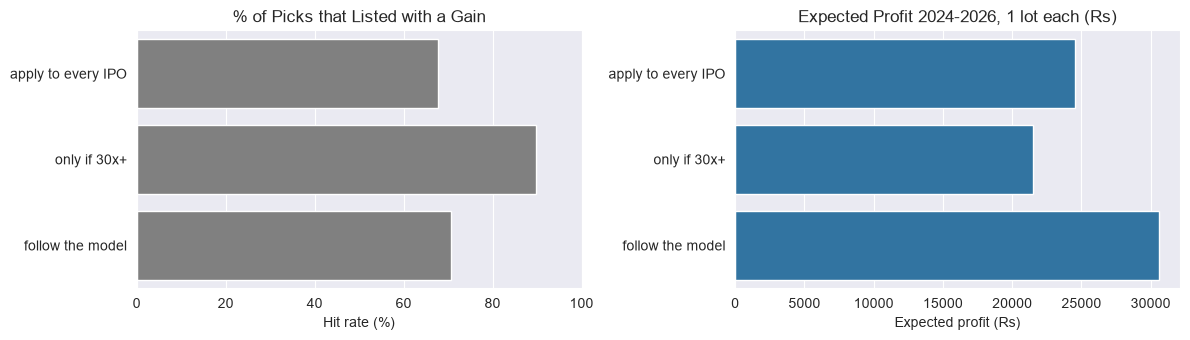

In [8]:
# only 3 strategies in the plot, with short names
show = ["Apply to every IPO", "Rule: subscribed 30x or more", "Model: random forest"]
r = results[(results["period"] == "2024-2026") & results["strategy"].isin(show)].copy()
r["strategy"] = r["strategy"].map({"Apply to every IPO": "apply to every IPO",
                                   "Rule: subscribed 30x or more": "only if 30x+",
                                   "Model: random forest": "follow the model"})

# left -> hit rate, right -> expected profit (best hit rate is not the best profit)
plt.figure(figsize=(12, 3.5))
plt.subplot(1, 2, 1)
sns.barplot(data=r, x="hit_rate", y="strategy", color="grey")
plt.title("% of Picks that Listed with a Gain")
plt.xlabel("Hit rate (%)")
plt.ylabel("")
plt.xlim(0, 100)
plt.subplot(1, 2, 2)
sns.barplot(data=r, x="expected_profit", y="strategy", color="tab:blue")
plt.title("Expected Profit 2024-2026, 1 lot each (Rs)")
plt.xlabel("Expected profit (Rs)")
plt.ylabel("")
plt.tight_layout()
plt.savefig(fig_dir + "12_strategy_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations (2024-2026):**

| Strategy | Applications | Listed with a gain | Expected allotments | Expected profit |
|---|---|---|---|---|
| Apply to every IPO | 202 | 67.8% | 62.7 | Rs 24,506 |
| Only if 30x+ | 98 | **89.8%** | 5.5 | Rs 21,505 |
| **Follow the model** | 187 | 70.6% | 52.6 | **Rs 30,588** |

- the **30x rule has the best hit rate but the worst profit** - its picks list high, but they're so
  oversubscribed that you expect only ~5 allotments out of 98 applications
- the model applies widely and only skips the IPOs it expects to list flat or down

## Step 2: Profit Over Time (2024-2026)

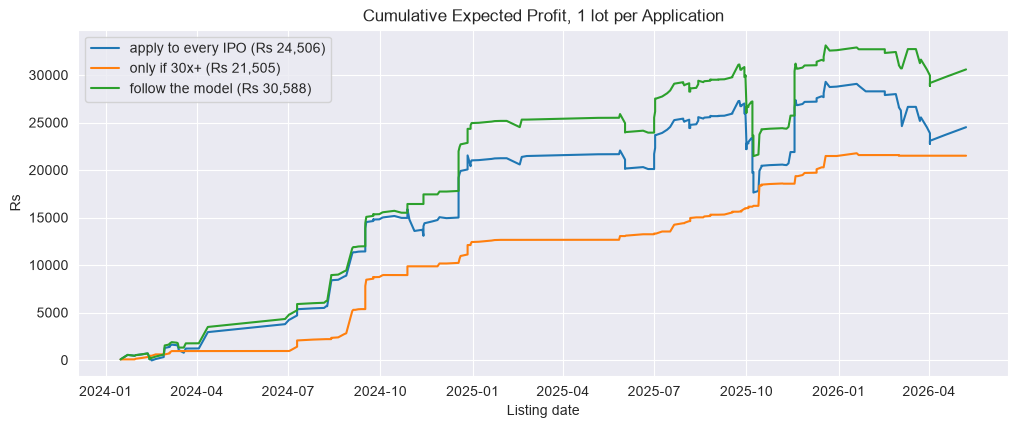

In [9]:
# test years in date order
t = test.sort_values("listing_date").reset_index(drop=True)
# expected profit of applying to each IPO
per_ipo = t["target_gain_pct"] / 100 * LOT * t["sub_rii"].map(allot_odds)
# True / False per IPO for every strategy
masks = {name: mask(t) for name, _, mask in plans}

# running total of profit over time (0 for IPOs the strategy skipped)
plt.figure(figsize=(12, 4.5))
for name, label in [("Apply to every IPO", "apply to every IPO"), ("Rule: subscribed 30x or more", "only if 30x+"),
                    ("Model: random forest", "follow the model")]:
    path = per_ipo.where(masks[name], 0).cumsum()
    plt.plot(t["listing_date"], path, label=f"{label} (Rs {path.iloc[-1]:,.0f})")
plt.title("Cumulative Expected Profit, 1 lot per Application")
plt.xlabel("Listing date")
plt.ylabel("Rs")
plt.legend()
plt.savefig(fig_dir + "13_cumulative_profit.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 3: Is the Edge Real or Luck? (Paired Bootstrap)

**What we do:** Resample the 2024-2026 IPOs with replacement 10,000 times, and each time compute the model's
extra profit over the other strategy.

**Why we do it:** 202 IPOs is not a big sample - a few lucky IPOs could make any strategy look good.

In [10]:
# is the model's extra profit real or luck? -> paired bootstrap
model_profit = per_ipo.where(masks["Model: random forest"], 0).to_numpy()
# fixed seed so the result is the same every run
rng = np.random.default_rng(0)
boot = []
for name in ["Apply to every IPO", "Rule: subscribed 30x or more", "Rule: tuned subscription cutoff"]:
    # extra profit of the model on each IPO compared to the other strategy
    diff = model_profit - per_ipo.where(masks[name], 0).to_numpy()
    # pick 202 IPOs at random with replacement, add up, do it 10000 times
    sums = np.array([rng.choice(diff, len(diff)).sum() for _ in range(10000)])
    # middle 95% of those totals; if the low end is above 0 the edge is real
    boot.append({"model vs": name, "extra profit": diff.sum(), "95% CI low": np.percentile(sums, 2.5),
                 "95% CI high": np.percentile(sums, 97.5), "% resamples model loses": (sums <= 0).mean() * 100})
pd.DataFrame(boot).set_index("model vs")

,extra profit,95% CI low,95% CI high,% resamples model loses
model vs,,,,
Apply to every IPO,"6,082.1","1,240.7","11,977.9",0.4
Rule: subscribed 30x or more,"9,083.1","-10,926.5","28,820.9",18.5
Rule: tuned subscription cutoff,"6,082.1","1,426.9","12,089.1",0.2


**Observations:**

| Model vs | Extra profit | 95% interval | Model loses in |
|---|---|---|---|
| Apply to every IPO | Rs 6,082 | Rs 1,241 to Rs 11,978 | 0.4% of resamples |
| Only if 30x+ | Rs 9,083 | Rs -10,927 to Rs 28,821 | 18.5% of resamples |

- vs applying to everything: the interval is **above zero** - the edge is real
- vs the 30x rule: more profit on average, but the interval includes zero - **not proven**

## Step 4: What Did the Model Skip in 2024-2026?

In [11]:
# IPOs the model said skip, and what really happened to them
skipped = t[~masks["Model: random forest"]]
print("skipped -:", len(skipped))
print("listed below offer -:", (skipped["target_gain_pct"] < 0).sum())
print("listed above offer -:", (skipped["target_gain_pct"] > 0).sum())
print("best one -:", round(skipped["target_gain_pct"].max(), 1), "%")
skipped[["ipo_name", "listing_date", "sub_total", "random_forest", "target_gain_pct"]]

skipped -: 15
listed below offer -: 9
listed above offer -: 5
best one -: 5.6 %


,ipo_name,listing_date,sub_total,random_forest,target_gain_pct
9,Entero Healthcare Solutions Limited,2024-02-16,1.5,-3.9,-2.3
19,Popular Vehicles & Services Ltd,2024-03-19,1.2,-3.5,-2.0
56,Godavari Biorefineries Limited,2024-10-30,1.8,-5.5,-12.5
57,Afcons Infrastructure Limited,2024-11-04,2.6,-3.3,-8.0
58,Sagility India Limited,2024-11-12,3.2,-3.3,3.5
59,ACME Solar Holdings Limited,2024-11-13,2.8,-4.0,-13.1
61,Niva Bupa Health Insurance Company Limited,2024-11-14,1.8,-4.7,5.6
62,Zinka Logistics Solution Limited (BlackBuck),2024-11-22,1.9,-4.6,2.2
63,NTPC Green Energy Limited,2024-11-27,2.4,-3.8,3.2
65,Suraksha Diagnostic Limited,2024-12-06,1.3,-3.4,-0.7


**Observation:** The model skipped **15** IPOs - 9 listed below the offer price, 1 flat and 5 above (the best
only **+5.6%**). All of them were low subscribed (about 1-3x).

## Step 5: How Sensitive is this to the Threshold?

**What we do:** Expected profit for every threshold, in both periods, compared with applying to every IPO.

**Why we do it:** If the profit only works at exactly -2%, it's probably luck.

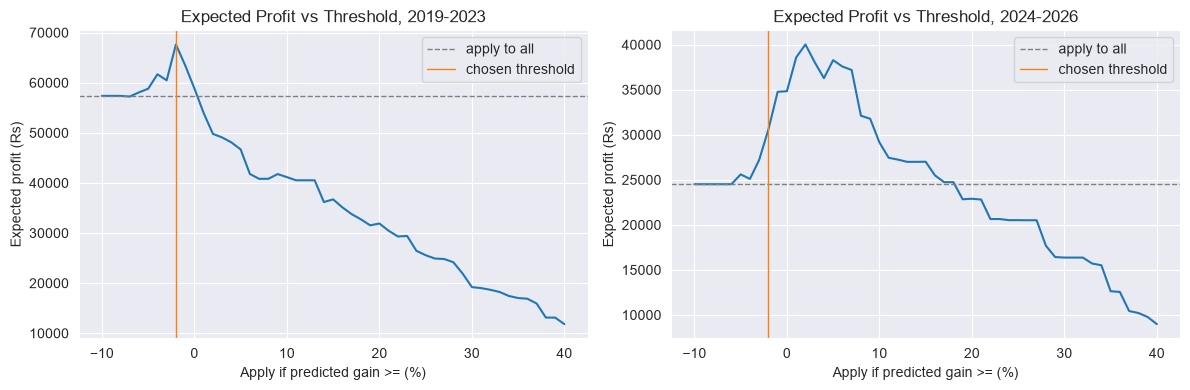

In [12]:
# does it only work at exactly the chosen threshold? -> profit for every threshold
curve = pd.DataFrame({"threshold": thresholds,
                      "2019-2023": [summarize(dev, dev["random_forest"] >= x)["expected_profit"] for x in thresholds],
                      "2024-2026": [summarize(t, t["random_forest"] >= x)["expected_profit"] for x in thresholds]})
# profit of applying to everything, drawn as a dashed line to compare
apply_all = {"2019-2023": summarize(dev, dev["sub_total"] > -1)["expected_profit"],
             "2024-2026": summarize(t, t["sub_total"] > -1)["expected_profit"]}

plt.figure(figsize=(12, 4))
for i, period in enumerate(["2019-2023", "2024-2026"]):
    plt.subplot(1, 2, i + 1)
    sns.lineplot(data=curve, x="threshold", y=period)
    plt.axhline(apply_all[period], color="grey", ls="--", lw=1, label="apply to all")
    # orange line = the threshold that was picked
    plt.axvline(model_t, color="tab:orange", lw=1, label="chosen threshold")
    plt.title(f"Expected Profit vs Threshold, {period}")
    plt.xlabel("Apply if predicted gain >= (%)")
    plt.ylabel("Expected profit (Rs)")
    plt.legend()
plt.tight_layout()
plt.savefig(fig_dir + "14_threshold_sensitivity.png", dpi=120, bbox_inches="tight")
plt.show()

**Observations:**
- **2019-2023:** the curve is spiky - -2% sits on a sharp peak. Anything from -4% to 0% beats applying to
  everything, but +1% or higher already falls below it. That's small sample noise, so the exact -2% shouldn't
  be over-read.
- **2024-2026:** every threshold from -5% up to about +17% beats applying to everything, and the best would have
  been around +2%. In a lower gain period being a bit pickier paid off, so -2% (picked on older data) was on
  the cautious side, not a lucky choice.

## Caveats

1. Allotment odds = 1 / retail subscription is an approximation - real odds depend on how many people bid for
   more than one lot
2. Assumes selling at the listing day open; brokerage, taxes and slippage are ignored (small for a 1 lot trade)
3. 2024-2026 is one period of ~200 IPOs - the edge over applying to everything is significant, the edge over
   the 30x rule is not
4. The forward test on Jun-Nov 2026 IPOs (collected after all of this was frozen) is in
   `reports/forward_test.md`

## Final Conclusion

| Question | Answer |
|---|---|
| Can the model predict the exact listing gain? | roughly - MAE ~16-20 pp, no better than a bucket lookup in 2024-26 |
| Can it rank IPOs from best to worst? | yes - Spearman 0.71 on unseen years |
| Does that make money? | yes - Rs 30,588 vs Rs 24,506 for applying to everything (2024-26), edge confirmed by bootstrap |
| Is the 30x rule a good strategy? | best hit rate, worst profit - the allotment lottery kills it |